In [5]:
%pip install spacy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [6]:
import sys
!{sys.executable} -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 20.6 MB/s  0:00:00m0:00:010:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [8]:
import spacy

print("spaCy imported successfully!")

spaCy imported successfully!


In [9]:
# Load the English language model

try:
    nlp = spacy.load("en_core_web_sm")
    print("spaCy English model loaded successfully!")

except OSError:
    print("English model not found.")
    print("Run: python -m spacy download en_core_web_sm")

spaCy English model loaded successfully!


In [10]:
# Sample input text

text = """
Apple Inc. is an American multinational technology company headquartered in
Cupertino, California.

Steve Jobs was a co-founder of Apple Inc. and played a key role in the development of the
Macintosh computer.

The Eiffel Tower is a wrought-iron lattice tower located on the Champ de Mars in Paris,
France.
"""

print(text)


Apple Inc. is an American multinational technology company headquartered in
Cupertino, California.

Steve Jobs was a co-founder of Apple Inc. and played a key role in the development of the
Macintosh computer.

The Eiffel Tower is a wrought-iron lattice tower located on the Champ de Mars in Paris,
France.



In [11]:
# Process the text using spaCy

doc = nlp(text)

In [12]:
# Extract and display named entities

print("Named Entities Found:\n")

for ent in doc.ents:
    print(
        f"Entity: {ent.text:<25} "
        f"Label: {ent.label_:<10} "
        f"Description: {spacy.explain(ent.label_)}"
    )

Named Entities Found:

Entity: Apple Inc.                Label: ORG        Description: Companies, agencies, institutions, etc.
Entity: American                  Label: NORP       Description: Nationalities or religious or political groups
Entity: Cupertino                 Label: GPE        Description: Countries, cities, states
Entity: California                Label: GPE        Description: Countries, cities, states
Entity: Steve Jobs                Label: PERSON     Description: People, including fictional
Entity: Apple Inc.                Label: ORG        Description: Companies, agencies, institutions, etc.
Entity: Macintosh                 Label: ORG        Description: Companies, agencies, institutions, etc.
Entity: The Eiffel Tower          Label: LOC        Description: Non-GPE locations, mountain ranges, bodies of water
Entity: the Champ de Mars         Label: FAC        Description: Buildings, airports, highways, bridges, etc.
Entity: Paris                     Label: GPE    

## Task 2 – Entity Counting and Basic Visualization

In [13]:
import matplotlib.pyplot as plt
from collections import Counter

In [14]:
# Count occurrences of each entity type

entity_counts = Counter(ent.label_ for ent in doc.ents)

print("Entity Type Counts:\n")

for entity_type, count in entity_counts.items():
    print(f"{entity_type}: {count}")

Entity Type Counts:

ORG: 3
NORP: 1
GPE: 4
PERSON: 1
LOC: 1
FAC: 1


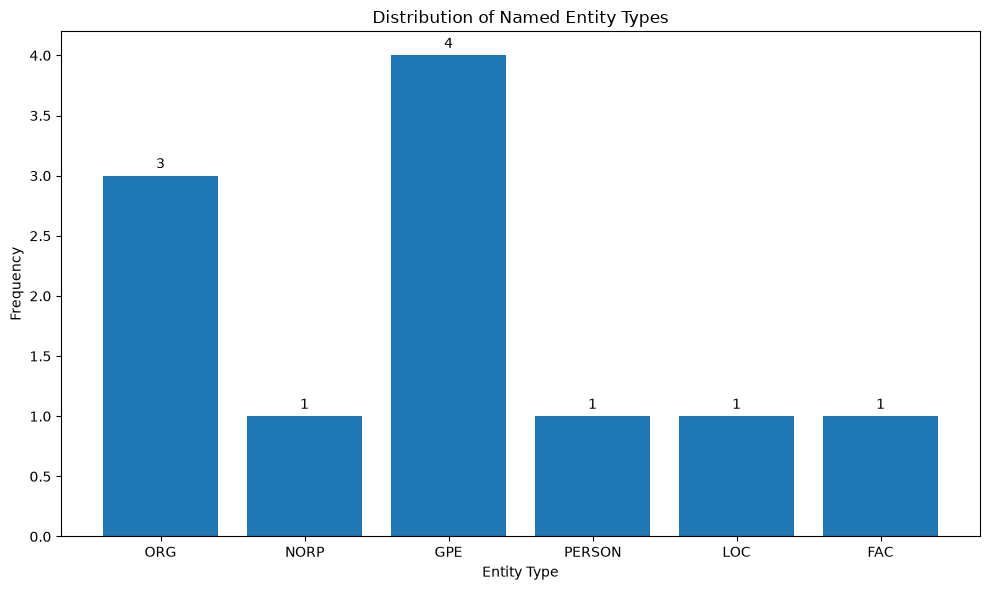

In [15]:
# Visualize entity distribution

fig, ax = plt.subplots(figsize=(10, 6))

labels = list(entity_counts.keys())
counts = list(entity_counts.values())

bars = ax.bar(labels, counts)

ax.set_title("Distribution of Named Entity Types")
ax.set_xlabel("Entity Type")
ax.set_ylabel("Frequency")

# Add values above the bars
ax.bar_label(bars, padding=3)

plt.tight_layout()
plt.show()

## Task 3 – Enhanced Entity Frequency Analysis

In [16]:
def analyze_entity_frequencies(doc):

    # Store entity and label combinations
    entity_frequency = Counter()

    for ent in doc.ents:

        # Use entity text and label as tuple
        key = (ent.text, ent.label_)

        entity_frequency[key] += 1

    # Sort entities by frequency in descending order
    sorted_entities = sorted(
        entity_frequency.items(),
        key=lambda item: item[1],
        reverse=True
    )

    return sorted_entities

In [17]:
# Analyze entity frequencies

frequency_results = analyze_entity_frequencies(doc)

print("Entity Frequency Analysis:\n")

for (entity, label), frequency in frequency_results:
    print(
        f"Entity: {entity:<25} "
        f"Label: {label:<10} "
        f"Frequency: {frequency}"
    )

Entity Frequency Analysis:

Entity: Apple Inc.                Label: ORG        Frequency: 2
Entity: American                  Label: NORP       Frequency: 1
Entity: Cupertino                 Label: GPE        Frequency: 1
Entity: California                Label: GPE        Frequency: 1
Entity: Steve Jobs                Label: PERSON     Frequency: 1
Entity: Macintosh                 Label: ORG        Frequency: 1
Entity: The Eiffel Tower          Label: LOC        Frequency: 1
Entity: the Champ de Mars         Label: FAC        Frequency: 1
Entity: Paris                     Label: GPE        Frequency: 1
Entity: France                    Label: GPE        Frequency: 1


In [19]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 27.6 MB/s  0:00:00m0:00:010:01
Note: you may need to restart the kernel to use updated packages.


In [20]:
import pandas as pd

frequency_df = pd.DataFrame(
    [
        {
            "Entity": entity,
            "Label": label,
            "Frequency": frequency
        }
        for (entity, label), frequency in frequency_results
    ]
)

display(frequency_df)

,Entity,Label,Frequency
0,Apple Inc.,ORG,2
1,American,NORP,1
2,Cupertino,GPE,1
3,California,GPE,1
4,Steve Jobs,PERSON,1
5,Macintosh,ORG,1
6,The Eiffel Tower,LOC,1
7,the Champ de Mars,FAC,1
8,Paris,GPE,1
9,France,GPE,1


## Task 4 – Multi-word Entity Analysis

In [21]:
# Filter multi-word entities

multi_word_entities = [
    ent for ent in doc.ents
    if len(ent.text.split()) > 1
]

print("Multi-word Entities:\n")

for ent in multi_word_entities:
    print(f"{ent.text:<25} {ent.label_}")

Multi-word Entities:

Apple Inc.                ORG
Steve Jobs                PERSON
Apple Inc.                ORG
The Eiffel Tower          LOC
the Champ de Mars         FAC


In [22]:
# Count multi-word entity types

multi_word_counts = Counter(
    ent.label_ for ent in multi_word_entities
)

print("Multi-word Entity Counts:\n")

for label, count in multi_word_counts.items():
    print(f"{label}: {count}")

Multi-word Entity Counts:

ORG: 2
PERSON: 1
LOC: 1
FAC: 1


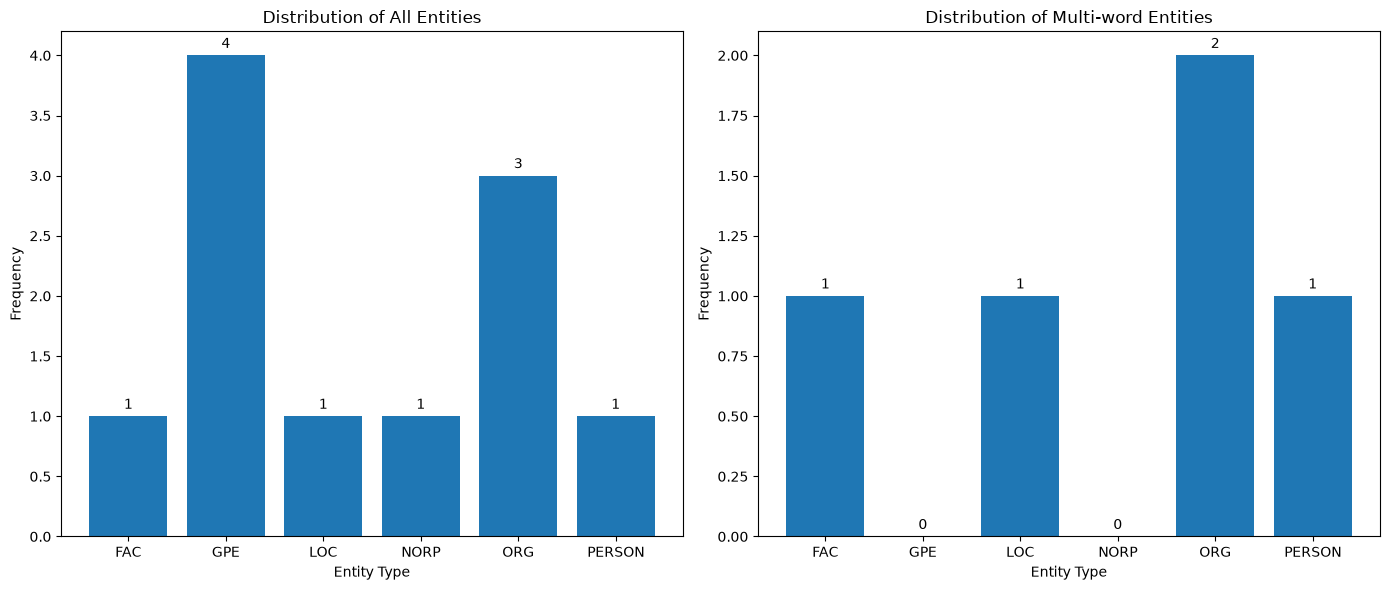

In [23]:
# Prepare comparison data

all_entity_counts = Counter(
    ent.label_ for ent in doc.ents
)

multi_word_counts = Counter(
    ent.label_ for ent in multi_word_entities
)

# Get all entity labels
all_labels = sorted(
    set(all_entity_counts.keys()) |
    set(multi_word_counts.keys())
)

# Prepare chart values
all_values = [
    all_entity_counts.get(label, 0)
    for label in all_labels
]

multi_values = [
    multi_word_counts.get(label, 0)
    for label in all_labels
]

# Create side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# First chart: All entities
bars1 = axes[0].bar(all_labels, all_values)

axes[0].set_title("Distribution of All Entities")
axes[0].set_xlabel("Entity Type")
axes[0].set_ylabel("Frequency")
axes[0].bar_label(bars1, padding=3)

# Second chart: Multi-word entities
bars2 = axes[1].bar(all_labels, multi_values)

axes[1].set_title("Distribution of Multi-word Entities")
axes[1].set_xlabel("Entity Type")
axes[1].set_ylabel("Frequency")
axes[1].bar_label(bars2, padding=3)

plt.tight_layout()
plt.show()

## Task 5 – Summary Statistics

In [24]:
# Calculate summary statistics

total_entities = len(doc.ents)

total_multi_word_entities = len(multi_word_entities)

total_single_word_entities = (
    total_entities - total_multi_word_entities
)

print("========== NER SUMMARY STATISTICS ==========")

print(f"Total Entities: {total_entities}")

print(
    f"Multi-word Entities: "
    f"{total_multi_word_entities}"
)

print(
    f"Single-word Entities: "
    f"{total_single_word_entities}"
)

print("\nEntity Distribution:")

for label, count in entity_counts.items():
    percentage = (count / total_entities) * 100

    print(
        f"{label}: {count} "
        f"({percentage:.2f}%)"
    )

print("\nMulti-word Entity Distribution:")

for label, count in multi_word_counts.items():
    print(f"{label}: {count}")

========== NER SUMMARY STATISTICS ==========
Total Entities: 11
Multi-word Entities: 5
Single-word Entities: 6

Entity Distribution:
ORG: 3 (27.27%)
NORP: 1 (9.09%)
GPE: 4 (36.36%)
PERSON: 1 (9.09%)
LOC: 1 (9.09%)
FAC: 1 (9.09%)

Multi-word Entity Distribution:
ORG: 2
PERSON: 1
LOC: 1
FAC: 1


In [25]:
# Create summary table

summary_data = {
    "Metric": [
        "Total Entities",
        "Multi-word Entities",
        "Single-word Entities"
    ],

    "Count": [
        total_entities,
        total_multi_word_entities,
        total_single_word_entities
    ]
}

summary_df = pd.DataFrame(summary_data)

display(summary_df)

,Metric,Count
0,Total Entities,11
1,Multi-word Entities,5
2,Single-word Entities,6


In [26]:
# Calculate multi-word entity percentage

if total_entities > 0:

    multi_word_percentage = (
        total_multi_word_entities / total_entities
    ) * 100

    single_word_percentage = (
        total_single_word_entities / total_entities
    ) * 100

else:
    multi_word_percentage = 0
    single_word_percentage = 0


print("========== COMPARATIVE ANALYSIS ==========")

print(
    f"Multi-word Entity Percentage: "
    f"{multi_word_percentage:.2f}%"
)

print(
    f"Single-word Entity Percentage: "
    f"{single_word_percentage:.2f}%"
)

========== COMPARATIVE ANALYSIS ==========
Multi-word Entity Percentage: 45.45%
Single-word Entity Percentage: 54.55%


### Question 1. What is Named Entity Recognition (NER) and why is it useful in text analysis? Provide examples of practical applications.

Answer: Named Entity Recognition (NER) is an NLP technique used to identify and classify important information in text, such as people's names, organizations, locations, dates, and other entities. It is useful because it helps extract meaningful information from large amounts of unstructured text without manually reading everything. For example, businesses can use NER to identify customer names and company details from emails, news organizations can track people and locations in articles, and healthcare systems can extract relevant information from medical documents

### Question 2. Explain how you implemented the entity counting system. What data structures did you use and why?

Answer: I implemented the entity counting system using Python's Counter data structure from the collections module. First, I processed the sample text using spaCy and extracted the recognized entities through the doc.ents property. I used entity labels as keys to count how many times each category appeared. For the enhanced analysis, I used tuples containing the entity text and its label. This approach made it easier to track individual entity frequencies and sort the results in descending order

### Question 3. Analyze your visualization approach.

Answer: The bar graph represents the number of recognized entities in each category, with entity types on the horizontal axis and their frequencies on the vertical axis. It makes it easy to compare categories and identify which types appear most frequently in the sample text. One improvement would be to display percentages along with counts, use different colors for each category, and include more detailed labels. This would make the visualization easier to interpret, especially when analyzing larger documents with many entity types.

### Question 4: Discuss your implementation of multi-word entity filtering

Answer: I identified multi-word entities by splitting each recognized entity into individual words and checking whether it contained more than one word. Entities such as Steve Jobs and Apple Inc. were included, while individual words such as Paris and California were excluded. After filtering, the distribution changed because only multi-word entities were considered in the comparison. This approach helps focus on complete names and phrases, but it should be used carefully because some important entities consist of only one word.

### Question 5. Evaluate the performance of the NER system.

Answer: The spaCy NER model successfully identified several entities from the sample text, including Apple Inc., Steve Jobs, Cupertino, California, Paris, and France. However, pretrained models may sometimes misclassify entities or fail to recognize certain names correctly, especially when dealing with unfamiliar terms or different contexts. The system could be improved by using a larger language model, providing more training examples, and adding custom entity patterns. Testing it with different types of text would also help evaluate its overall performance.